# LIBRARIES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [2]:
filepath = "D:\ict AI ML\quickkart\quickkart_customers.csv"

<>:1: SyntaxWarning: invalid escape sequence '\i'
<>:1: SyntaxWarning: invalid escape sequence '\i'
C:\Users\DELL\AppData\Local\Temp\ipykernel_14788\2819849826.py:1: SyntaxWarning: invalid escape sequence '\i'
  filepath = "D:\ict AI ML\quickkart\quickkart_customers.csv"


# EDA

In [3]:
df_quick = pd.read_csv(filepath)
df_quick.head(10)

,Customer_ID,Age,Gender,City,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
0,C0258,29.0,Female,Kozhikode,Basic,Debit Card,55900.0,6.0,523.0,3143.0
1,C0758,36.0,Male,Thrissur,Silver,UPI,47900.0,21.0,855.0,16395.0
2,C0993,18.0,Male,Thrissur,Basic,UPI,32600.0,2.0,491.0,1007.0
3,C1171,32.0,Female,Kochi,Gold,Credit Card,32900.0,12.0,1776.0,22554.0
4,C1069,34.0,Female,Kochi,Gold,Cash on Delivery,81000.0,10.0,426.0,3915.0
5,C0800,24.0,Male,Kozhikode,Gold,Credit Card,32100.0,14.0,480.0,6344.0
6,C1440,29.0,Male,Kollam,Silver,Debit Card,38000.0,16.0,260.0,3890.0
7,C1422,42.0,Female,Kollam,Gold,Debit Card,40900.0,18.0,1302.0,25298.0
8,C1200,18.0,Female,Kochi,Silver,Cash on Delivery,66400.0,8.0,440.0,3643.0
9,C0516,43.0,Male,kochi,Basic,Debit Card,33300.0,8.0,482.0,3733.0


In [4]:
df_quick.shape

(1500, 10)

In [5]:
df_quick.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Customer_ID       1500 non-null   object 
 1   Age               1419 non-null   float64
 2   Gender            1449 non-null   object 
 3   City              1434 non-null   object 
 4   Membership        1500 non-null   object 
 5   Payment_Mode      1405 non-null   object 
 6   Monthly_Income    1346 non-null   float64
 7   Orders_Last_Year  1500 non-null   float64
 8   Avg_Order_Value   1376 non-null   float64
 9   Total_Spent       1500 non-null   float64
dtypes: float64(5), object(5)
memory usage: 117.3+ KB


In [6]:
df_quick.describe()

,Age,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
count,1419.000000,1346.000000,1500.000000,1376.000000,1500.000000
mean,34.248062,43418.424963,8.986667,817.260901,5723.821333
std,10.554268,62967.813712,15.567661,1805.319096,6497.750986
min,-3.000000,5500.000000,1.000000,81.000000,157.000000
25%,27.000000,24100.000000,4.000000,401.000000,1937.750000
50%,34.000000,33600.000000,7.000000,579.500000,3820.500000
75%,41.000000,47300.000000,11.000000,868.250000,7280.250000
max,150.000000,900000.000000,310.000000,35000.000000,85073.000000


Observation: 1) Age has a negative minimum value and maximum of 150, which are impossible.

2)All other three columns have a very low median(50%) compared to their max value.

In [7]:
df_quick.describe(include='object')

,Customer_ID,Gender,City,Membership,Payment_Mode
count,1500,1449,1434,1500,1405
unique,1465,5,17,9,5
top,C0924,Female,Kochi,Basic,UPI
freq,2,727,358,788,604


In [8]:
df_quick.isna().sum()

Customer_ID           0
Age                  81
Gender               51
City                 66
Membership            0
Payment_Mode         95
Monthly_Income      154
Orders_Last_Year      0
Avg_Order_Value     124
Total_Spent           0
dtype: int64

Observation: Understood where all are missing values

In [9]:
df_quick.duplicated().sum()

np.int64(35)

Observation: Understood there are 35 duplicate rows.

In [10]:
num_cols = df_quick.select_dtypes(include=["number"]).columns
cat_cols = df_quick.select_dtypes(include=["object"]).columns

In [11]:
for col in cat_cols:
  print(df_quick[col].value_counts(dropna=False))

Customer_ID
C0924    2
C1029    2
C0781    2
C0070    2
C1416    2
        ..
C0953    1
C0473    1
C1212    1
C0239    1
C0934    1
Name: count, Length: 1465, dtype: int64
Gender
Female    727
Male      674
NaN        51
Other      38
F           7
M           3
Name: count, dtype: int64
City
Kochi          358
Trivandrum     230
Kozhikode      213
Thrissur       175
Kollam         144
Kannur         114
Alappuzha      113
Palakkad        73
NaN             66
kochi            3
Kochi            2
Trivandrum       2
kozhikode        2
TRIVANDRUM       1
kollam           1
KOCHI            1
KOLLAM           1
thrissur         1
Name: count, dtype: int64
Membership
Basic       788
Silver      382
Gold        192
Platinum    124
silver        5
SILVER        4
GOLD          2
basic         2
PLATINUM      1
Name: count, dtype: int64
Payment_Mode
UPI                 604
Cash on Delivery    258
Credit Card         248
Debit Card          209
NaN                  95
Net Banking          86

Observation: 1) Gender column has same values in different form (Male, M, Female and F)

2) Similarly in City column also, such as Kochi is repeated in different forms (Kochi, kochi, KOCHI, Kochi , etc

3) Also in Membership column, (Basic, basic, silver, SILVER) etc

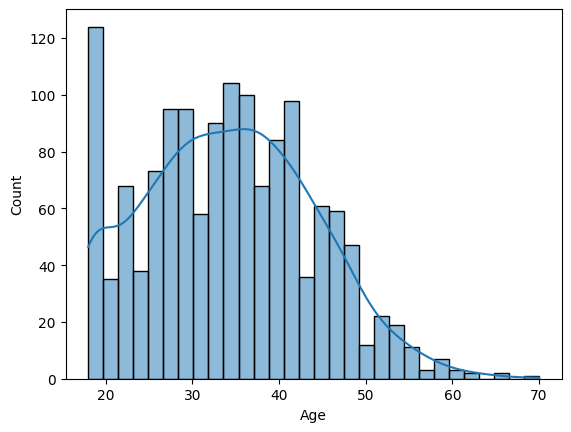

In [12]:
sns.histplot(df_quick["Age"].where(df_quick["Age"].between(10,100)), bins=30, kde=True)
plt.show()

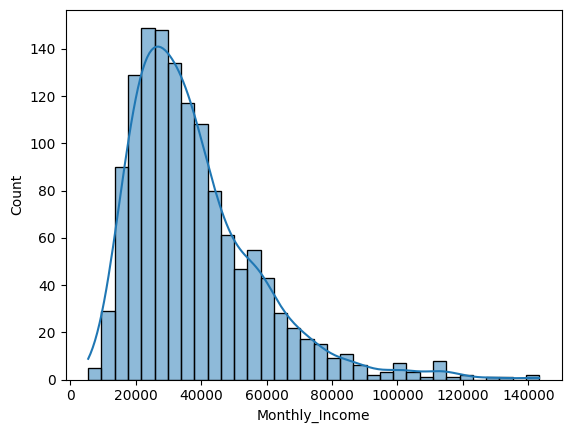

In [13]:
sns.histplot(df_quick["Monthly_Income"].where(df_quick["Monthly_Income"].between(0,200000)), kde=True)
plt.show()

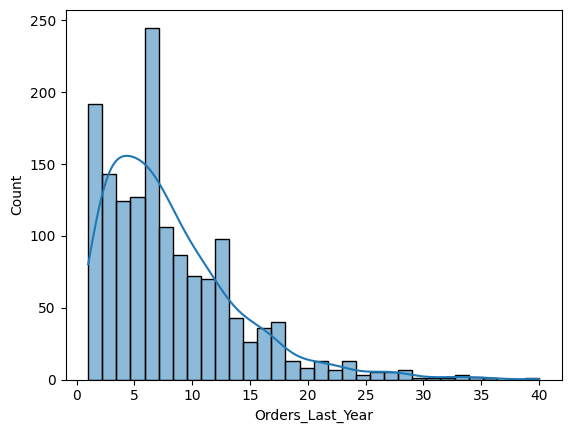

In [14]:
sns.histplot(df_quick["Orders_Last_Year"].where(df_quick["Orders_Last_Year"].between(0,50)), kde=True)
plt.show()

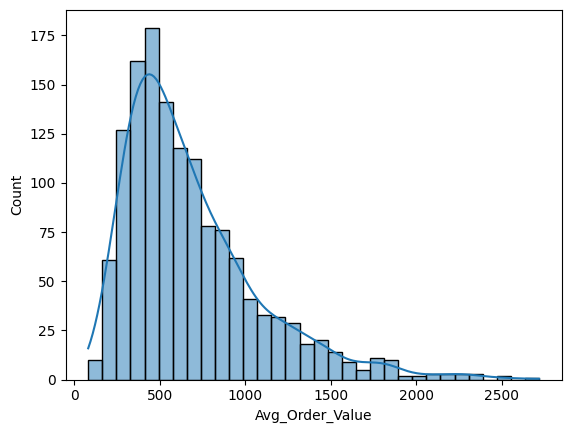

In [15]:
sns.histplot(df_quick["Avg_Order_Value"].where(df_quick["Avg_Order_Value"].between(0,5000)), kde=True)
plt.show()

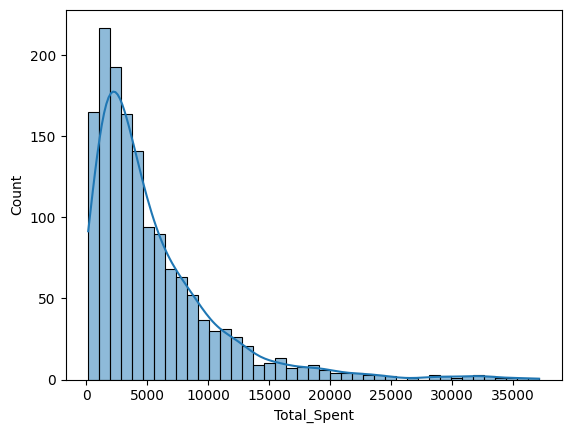

In [16]:
sns.histplot(df_quick["Total_Spent"].where(df_quick["Total_Spent"].between(0,40000)), kde=True)
plt.show()

In [17]:
print(df_quick["Age"].skew())
print(df_quick["Monthly_Income"].skew())
print(df_quick["Orders_Last_Year"].skew())
print(df_quick["Avg_Order_Value"].skew())
print(df_quick["Total_Spent"].skew())

1.330100857050687
9.969281505253235
14.04589029116431
14.0119370142517
4.115137475497203


Observation: The plots and skew value shows that mainly the columns, Monthly Income, Avg Order Value and Orders Last Year are heavily skewed (> 10) and the best way is to replace with median,

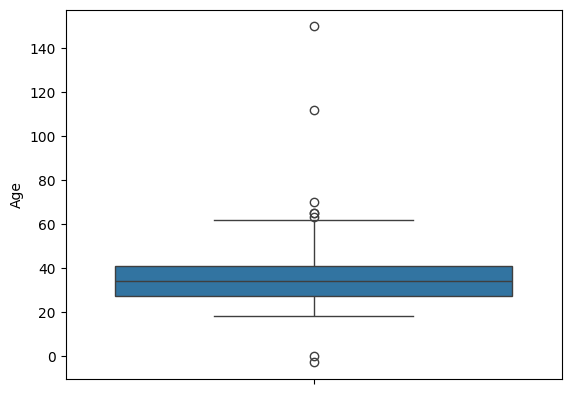

In [18]:
sns.boxplot(df_quick["Age"])
plt.show()

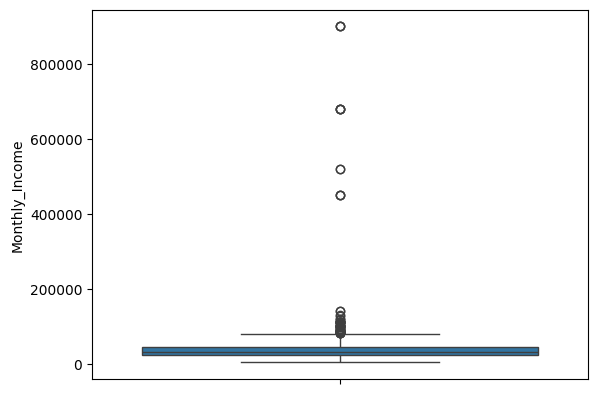

In [19]:
sns.boxplot(df_quick["Monthly_Income"])
plt.show()

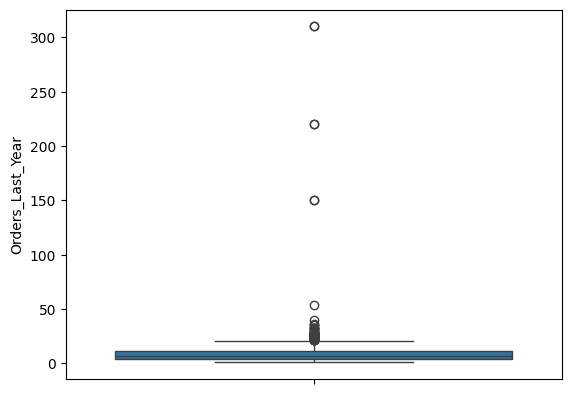

In [20]:
sns.boxplot(df_quick["Orders_Last_Year"])
plt.show()

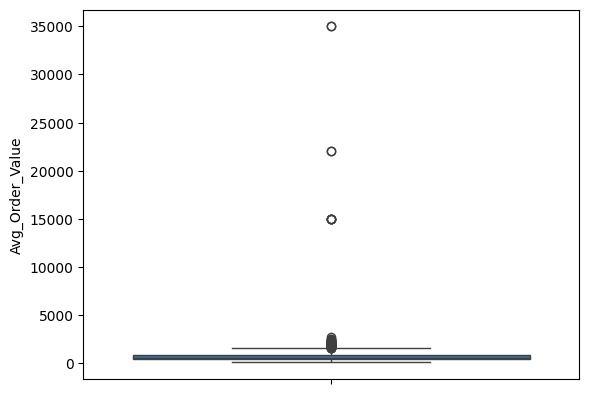

In [21]:
sns.boxplot(df_quick["Avg_Order_Value"])
plt.show()

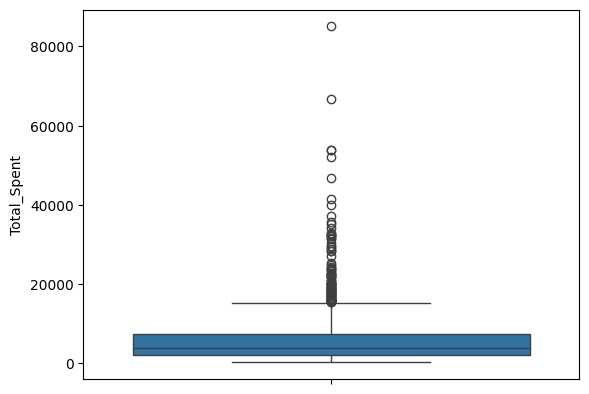

In [22]:
sns.boxplot(df_quick["Total_Spent"])
plt.show()

Observation: Each numerical column has outliers.

In [23]:
for col in num_cols:
    Q1, Q3 = df_quick[col].quantile([.25, .75])
    IQR = Q3 - Q1
    n = ((df_quick[col] < Q1 - 1.5*IQR) | (df_quick[col] > Q3 + 1.5*IQR)).sum()
    print(col, n)

Age 8
Monthly_Income 60
Orders_Last_Year 57
Avg_Order_Value 63
Total_Spent 90


# DATA CLEANING

In [24]:
df_quick["Gender"] = df_quick["Gender"].replace('F', 'Female')
df_quick["Gender"] = df_quick["Gender"].replace('M', 'Male')

In [25]:
df_quick["City"] = df_quick["City"].replace('kochi', 'Kochi')
df_quick["City"] = df_quick["City"].replace('Kochi ', 'Kochi')
df_quick["City"] = df_quick["City"].replace('KOCHI', 'Kochi')
df_quick["City"] = df_quick["City"].replace('KOLLAM', 'Kollam')
df_quick["City"] = df_quick["City"].replace('kollam', 'Kollam')
df_quick["City"] = df_quick["City"].replace('Trivandrum ', 'Trivandrum')
df_quick["City"] = df_quick["City"].replace('TRIVANDRUM', 'Trivandrum')
df_quick["City"] = df_quick["City"].replace('thrissur', 'Thrissur')
df_quick["City"] = df_quick["City"].replace('kozhikode', 'Kozhikode')

In [26]:
#formatting mixed categorical column names

df_quick["Membership"] = df_quick["Membership"].replace('SILVER', 'Silver')
df_quick["Membership"] = df_quick["Membership"].replace('silver', 'Silver')
df_quick["Membership"] = df_quick["Membership"].replace('PLATINUM', 'Platinum')
df_quick["Membership"] = df_quick["Membership"].replace('basic', 'Basic')
df_quick["Membership"] = df_quick["Membership"].replace('GOLD', 'Gold')

In [27]:
# removing duplicated rows and reseting index
df_quick.drop_duplicates(inplace=True, ignore_index=True)
df_quick.duplicated().sum()

np.int64(0)

In [28]:
# replacing null values in age, monthly income and avg order value column by median

for col in ["Age", "Monthly_Income", "Avg_Order_Value"]:
   df_quick[col] = df_quick[col].fillna(df_quick[col].median())

In [29]:
# replacing null values in Gender, City, Payment mode columns by mode.

for col in ["Gender", "City", "Payment_Mode"]:
  df_quick[col] = df_quick[col].fillna(df_quick[col].mode()[0])

In [30]:
#replacing outliers in age column with logic, since age cant be negative and cant go upto 150 (max)
#converting ages less than 18 and greater than 100 into NaN and filling it with median

wrong_age = (df_quick["Age"] < 18) | (df_quick["Age"] > 100)
df_quick.loc[wrong_age, "Age"] = np.nan
df_quick["Age"] = df_quick["Age"].fillna(df_quick["Age"].median())

In [31]:
num_cols_tocap = ["Monthly_Income", "Orders_Last_Year", "Avg_Order_Value", "Total_Spent"]

Q1 = df_quick[num_cols_tocap].quantile(0.25)
Q3 = df_quick[num_cols_tocap].quantile(0.75)

IQR = Q3 - Q1

upperlimit = Q3 + 1.5 * IQR
lowerlimit = Q1 - 1.5 * IQR

In [32]:
#replacing outliers in other numerical columns with upper or lower limits
df_quick[num_cols_tocap] = df_quick[num_cols_tocap].clip(lower=lowerlimit, upper=upperlimit, axis=1)

In [33]:
df_quick["Gender"].value_counts()

Gender
Female    772
Male      657
Other      36
Name: count, dtype: int64

In [34]:
df_quick.head()

,Customer_ID,Age,Gender,City,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
0,C0258,29.0,Female,Kozhikode,Basic,Debit Card,55900.0,6.0,523.0,3143.0
1,C0758,36.0,Male,Thrissur,Silver,UPI,47900.0,21.0,855.0,15163.5
2,C0993,18.0,Male,Thrissur,Basic,UPI,32600.0,2.0,491.0,1007.0
3,C1171,32.0,Female,Kochi,Gold,Credit Card,32900.0,12.0,1457.0,15163.5
4,C1069,34.0,Female,Kochi,Gold,Cash on Delivery,74350.0,10.0,426.0,3915.0


# ENCODING

In [35]:
#label encoding "Gender" column

le = LabelEncoder()

df_quick["Gender"] = le.fit_transform(df_quick["Gender"])

df_quick["Gender"].unique()

array([0, 1, 2])

In [36]:
# ordinal encoding "Membership" column
enc_mem = OrdinalEncoder(
    categories = [["Basic", "Silver", "Gold", "Platinum"]]
)

df_quick["Membership"] = enc_mem.fit_transform(df_quick[["Membership"]])

In [37]:
# one hot encoding "Payment_Mode" and "City" columns, since they have no order
enc_pay = OneHotEncoder()

enc_pay_data = enc_pay.fit_transform(df_quick[["Payment_Mode"]])

enc_pay_df = pd.DataFrame(
    enc_pay_data.toarray(),
    columns = enc_pay.get_feature_names_out(["Payment_Mode"]),
    index = df_quick.index
)

df_quick = pd.concat([df_quick.drop("Payment_Mode", axis=1), enc_pay_df], axis=1)

In [38]:
enc_city = OneHotEncoder()

enc_city_data = enc_city.fit_transform(df_quick[["City"]])

enc_city_df = pd.DataFrame(
    enc_city_data.toarray(),
    columns = enc_city.get_feature_names_out(["City"]),
    index = df_quick.index
)

df_quick = pd.concat([df_quick.drop("City", axis=1), enc_city_df], axis=1)

In [39]:
df_quick.columns


Index(['Customer_ID', 'Age', 'Gender', 'Membership', 'Monthly_Income',
       'Orders_Last_Year', 'Avg_Order_Value', 'Total_Spent',
       'Payment_Mode_Cash on Delivery', 'Payment_Mode_Credit Card',
       'Payment_Mode_Debit Card', 'Payment_Mode_Net Banking',
       'Payment_Mode_UPI', 'City_Alappuzha', 'City_Kannur', 'City_Kochi',
       'City_Kollam', 'City_Kozhikode', 'City_Palakkad', 'City_Thrissur',
       'City_Trivandrum'],
      dtype='object')

# SCALING

In [40]:
# assuming "Gender" as target column
X = df_quick.drop(columns=["Customer_ID", "Gender"])
y = df_quick["Gender"]

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [42]:
scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])